# EWU Knowledge Base Pipeline

A reproducible walkthrough of public document collection, privacy filtering, semantic indexing and course prerequisite references. Run the pipeline first, then open this notebook using the dedicated project environment. No generated answers are used.


In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
from ewu_kb.common import setup_paths, load_stats, read_csv
setup_paths()
assert (ROOT/"reports/summary.json").exists(), "Run the pipeline and report first"
import pandas as pd


## Sources and provenance

The manifest records public URLs, retrieval timestamps, sizes and checksums. Raw downloads remain local. A successful HTTP response can still contain an empty content panel; the extraction report exposes that case.


In [2]:
manifest = pd.DataFrame(read_csv("reports/manifest.csv"))
manifest[["id","status","bytes","retrieved_at","sha256"]]


,id,status,bytes,retrieved_at,sha256
0,S1,200,5285700,2026-10-26T03:40:38.898775+06:00,d53ec61af6f9b9dbacab9f6d190420c13ee1dfa679ba0c...
1,W1,200,126649,2026-10-26T03:41:54.366536+06:00,91f7fde9bd3035ce68805c79945045f224e7db270e8b89...
2,W2,200,99024,2026-10-26T03:41:54.901656+06:00,03ba76cd6cbe74e5d8e568da0fac38cbe9dd4ea4697ff3...
3,W3,200,114161,2026-10-26T03:41:58.302161+06:00,09179c31d62e9b3bcd00030472d80f2a43af7cbb07536e...
4,W4,200,101798,2026-10-26T03:42:01.427955+06:00,91cc271c0da1c5525c5a474e4f4373d915ed2c761af7c3...
5,W5,200,169457,2026-10-26T03:42:03.889869+06:00,865c995b02ad3cda2711d49ec8407b2e347c7962e00672...
6,W6,200,155605,2026-10-26T03:42:06.885979+06:00,9be6c78724da0135ea639bc04e37cdf14e8d361b991468...
7,W7,200,97644,2026-10-26T03:42:10.724559+06:00,a85167da2981513586e9162ae14fa56bf6f9f36f00b07b...
8,W8,200,129330,2026-10-26T03:42:12.984133+06:00,9aca738315e980ebc37e56eb9f155dd3d941926eb179ac...
9,C1,200,334321,2026-10-26T03:42:16.651127+06:00,882771f826ca89483f41489ac3e345cbb27ea3ed83d457...


In [3]:
{stage: load_stats(stage) for stage in ["extract","clean","chunk_200","chunk_300"]}


{'extract': {'units_by_source': {'S1': 524,
   'W1': 62,
   'W2': 10,
   'W3': 14,
   'W4': 2,
   'W5': 143,
   'W6': 91,
   'W7': 0,
   'W8': 34,
   'C1': 425,
   'C2': 191,
   'C3': 235,
   'C4': 29,
   'P1': 6,
   'P2': 5,
   'P3': 11,
   'P4': 10},
  'units': 1792,
  'possibly_scanned': [{'doc_id': 'S1', 'page': 3},
   {'doc_id': 'S1', 'page': 7},
   {'doc_id': 'S1', 'page': 8},
   {'doc_id': 'S1', 'page': 9},
   {'doc_id': 'S1', 'page': 19},
   {'doc_id': 'S1', 'page': 20}],
  'empty_sources_quarantined': ['W7'],
  'status': 'needs_review',
  'fallback_units': 0},
 'clean': {'rules': {'page_number': 53088,
   'hyphen_joins': 63,
   'repeated_margin': 8103},
  'large_losses': [{'doc_id': 'S1',
    'page': 1,
    'block': None,
    'loss_fraction': 0.452},
   {'doc_id': 'S1', 'page': 3, 'block': None, 'loss_fraction': 1.0},
   {'doc_id': 'S1', 'page': 6, 'block': None, 'loss_fraction': 0.431},
   {'doc_id': 'S1', 'page': 7, 'block': None, 'loss_fraction': 1.0},
   {'doc_id': 'S1', '

## Structured records and version differences

Course editions remain separate. Prerequisite expressions preserve alternatives and non-course conditions. Comparing explicit rule values exposes why an older bulletin should not automatically settle a current-policy question.


In [4]:
courses = pd.DataFrame(read_csv("data/processed/courses.csv"))
courses[courses.source == "C1"][["code","title","credits_total","prerequisites","prerequisite_expression"]].head(12)


,code,title,credits_total,prerequisites,prerequisite_expression
0,CSE103,Structured Programming,4.5,[],None
1,CSE106,Discrete Mathematics,3,"[""CSE103""]",CSE103 Structured Programming
2,CSE110,Object Oriented Programming,4.5,"[""CSE106""]",CSE106 Discrete Mathematics
3,CSE200,Computer-Aided Engineering Drawing,1,[],None
4,CSE207,Data Structures,4,"[""CSE110""]",CSE110 Object Oriented Programming
5,CSE209,Electrical Circuits,4,[],None
6,CSE246,Algorithms,4.5,"[""CSE207""]",CSE207 Data Structures
7,CSE251,Electronic Circuits,4,"[""CSE209""]",CSE209 Electrical Circuits
8,CSE302,Database Systems,4.5,"[""CSE106""]",CSE106Discrete Mathematics
9,CSE325,Operating Systems,4,[],None


In [5]:
pd.DataFrame(read_csv("data/processed/conflicts.csv"))


,rule,bulletin_value,web_value,bulletin_page,web_url,status
0,grade_point_A,4.00,3.75,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
1,grade_point_A-,3.70,3.50,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
2,grade_point_B+,3.30,3.25,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
3,grade_point_B-,2.70,2.75,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
4,grade_point_C,2.00,2.25,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
5,grade_point_C+,2.30,2.50,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
6,grade_point_D,1.00,2.00,[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
7,score_bounds_A,"[90.0, 97.0]","[75.0, 80.0]",[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
8,score_bounds_A+,"[97.0, 100.0]",[80.0],[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date
9,score_bounds_A-,"[87.0, 90.0]","[70.0, 75.0]",[216],https://www.ewubd.edu/grades-rules-and-regulat...,extracted_discrepancy_verify_effective_date


## Privacy and annotation

Regex and Transformers NER run before embedding. Counts show detector activity; precision and recall require independent human labels. Detection is not a guarantee of anonymization. The private annotation helper and original review pages must not be published.


In [6]:
load_stats("pii")


{'redactions': 1796,
 'by_type': {'PERSON': 1791, 'PHONE': 4, 'EMAIL': 1},
 'by_detector': {'ner': 1791, 'regex': 5},
 'fragments': 4531,
 'fingerprint': 'ac0bd61ce55496840d828514d5076dba129e64e9ce6eabd8443deac513a3bffb',
 'threshold': 0.85,
 'device': 'cuda',
 'precision_recall': 'pending human annotation; detection is not a guarantee of anonymization'}

## Retrieval comparison

Two embedding models use normalized vectors in Chroma. Nominal chunk settings are 200 and 300, with the second capped at 254 content tokens to avoid MiniLM truncation. Freeze the 40 human-reviewed gold questions before evaluation; unreviewed data produces pending states.


In [7]:
load_stats("evaluate")


{'annotation': {'status': 'complete',
  'n': 99,
  'raw_n': 100,
  'excluded': [{'chunk_id': 'd78185941577bc9600424f29a9b28862',
    'excel_row': 48,
    'reason': 'The entire passage is Credit, a detached table-column header with insufficient topic context and an inherited unrelated course heading.'}],
  'agreement': 0.9191919191919192,
  'raw_agreement_including_flagged_fragments': 0.92,
  'confusion': [{'human': 'conduct_discipline',
    'rule': 'conduct_discipline',
    'count': 4},
   {'human': 'course_info', 'rule': 'course_info', 'count': 74},
   {'human': 'course_info', 'rule': 'other', 'count': 2},
   {'human': 'graduation', 'rule': 'course_info', 'count': 2},
   {'human': 'graduation', 'rule': 'other', 'count': 1},
   {'human': 'online_classes', 'rule': 'online_classes', 'count': 1},
   {'human': 'other', 'rule': 'conduct_discipline', 'count': 1},
   {'human': 'other', 'rule': 'fees_refunds', 'count': 1},
   {'human': 'other', 'rule': 'graduation', 'count': 1},
   {'human': '

## Prerequisite reference graph

Edges point from prerequisite to course. Amber nodes are unresolved references in the catalogue. A dependency chain is not a substitute for reviewing OR expressions or credit-completion conditions.


In [8]:
from ewu_kb.graph import build_graph, query
graph = build_graph(read_csv("data/processed/courses.csv"), read_csv("data/processed/prereq_edges.csv"))
query(graph, "CSE103", "unlocks")


['CSE106',
 'CSE110',
 'CSE207',
 'CSE246',
 'CSE302',
 'CSE313',
 'CSE347',
 'CSE366',
 'CSE370',
 'CSE405',
 'CSE406',
 'CSE412',
 'CSE420',
 'CSE422',
 'CSE423',
 'CSE425',
 'CSE428',
 'CSE430',
 'CSE438',
 'CSE453',
 'CSE457',
 'CSE471',
 'CSE475',
 'CSE477',
 'CSE479',
 'CSE483',
 'CSE484',
 'CSE486']

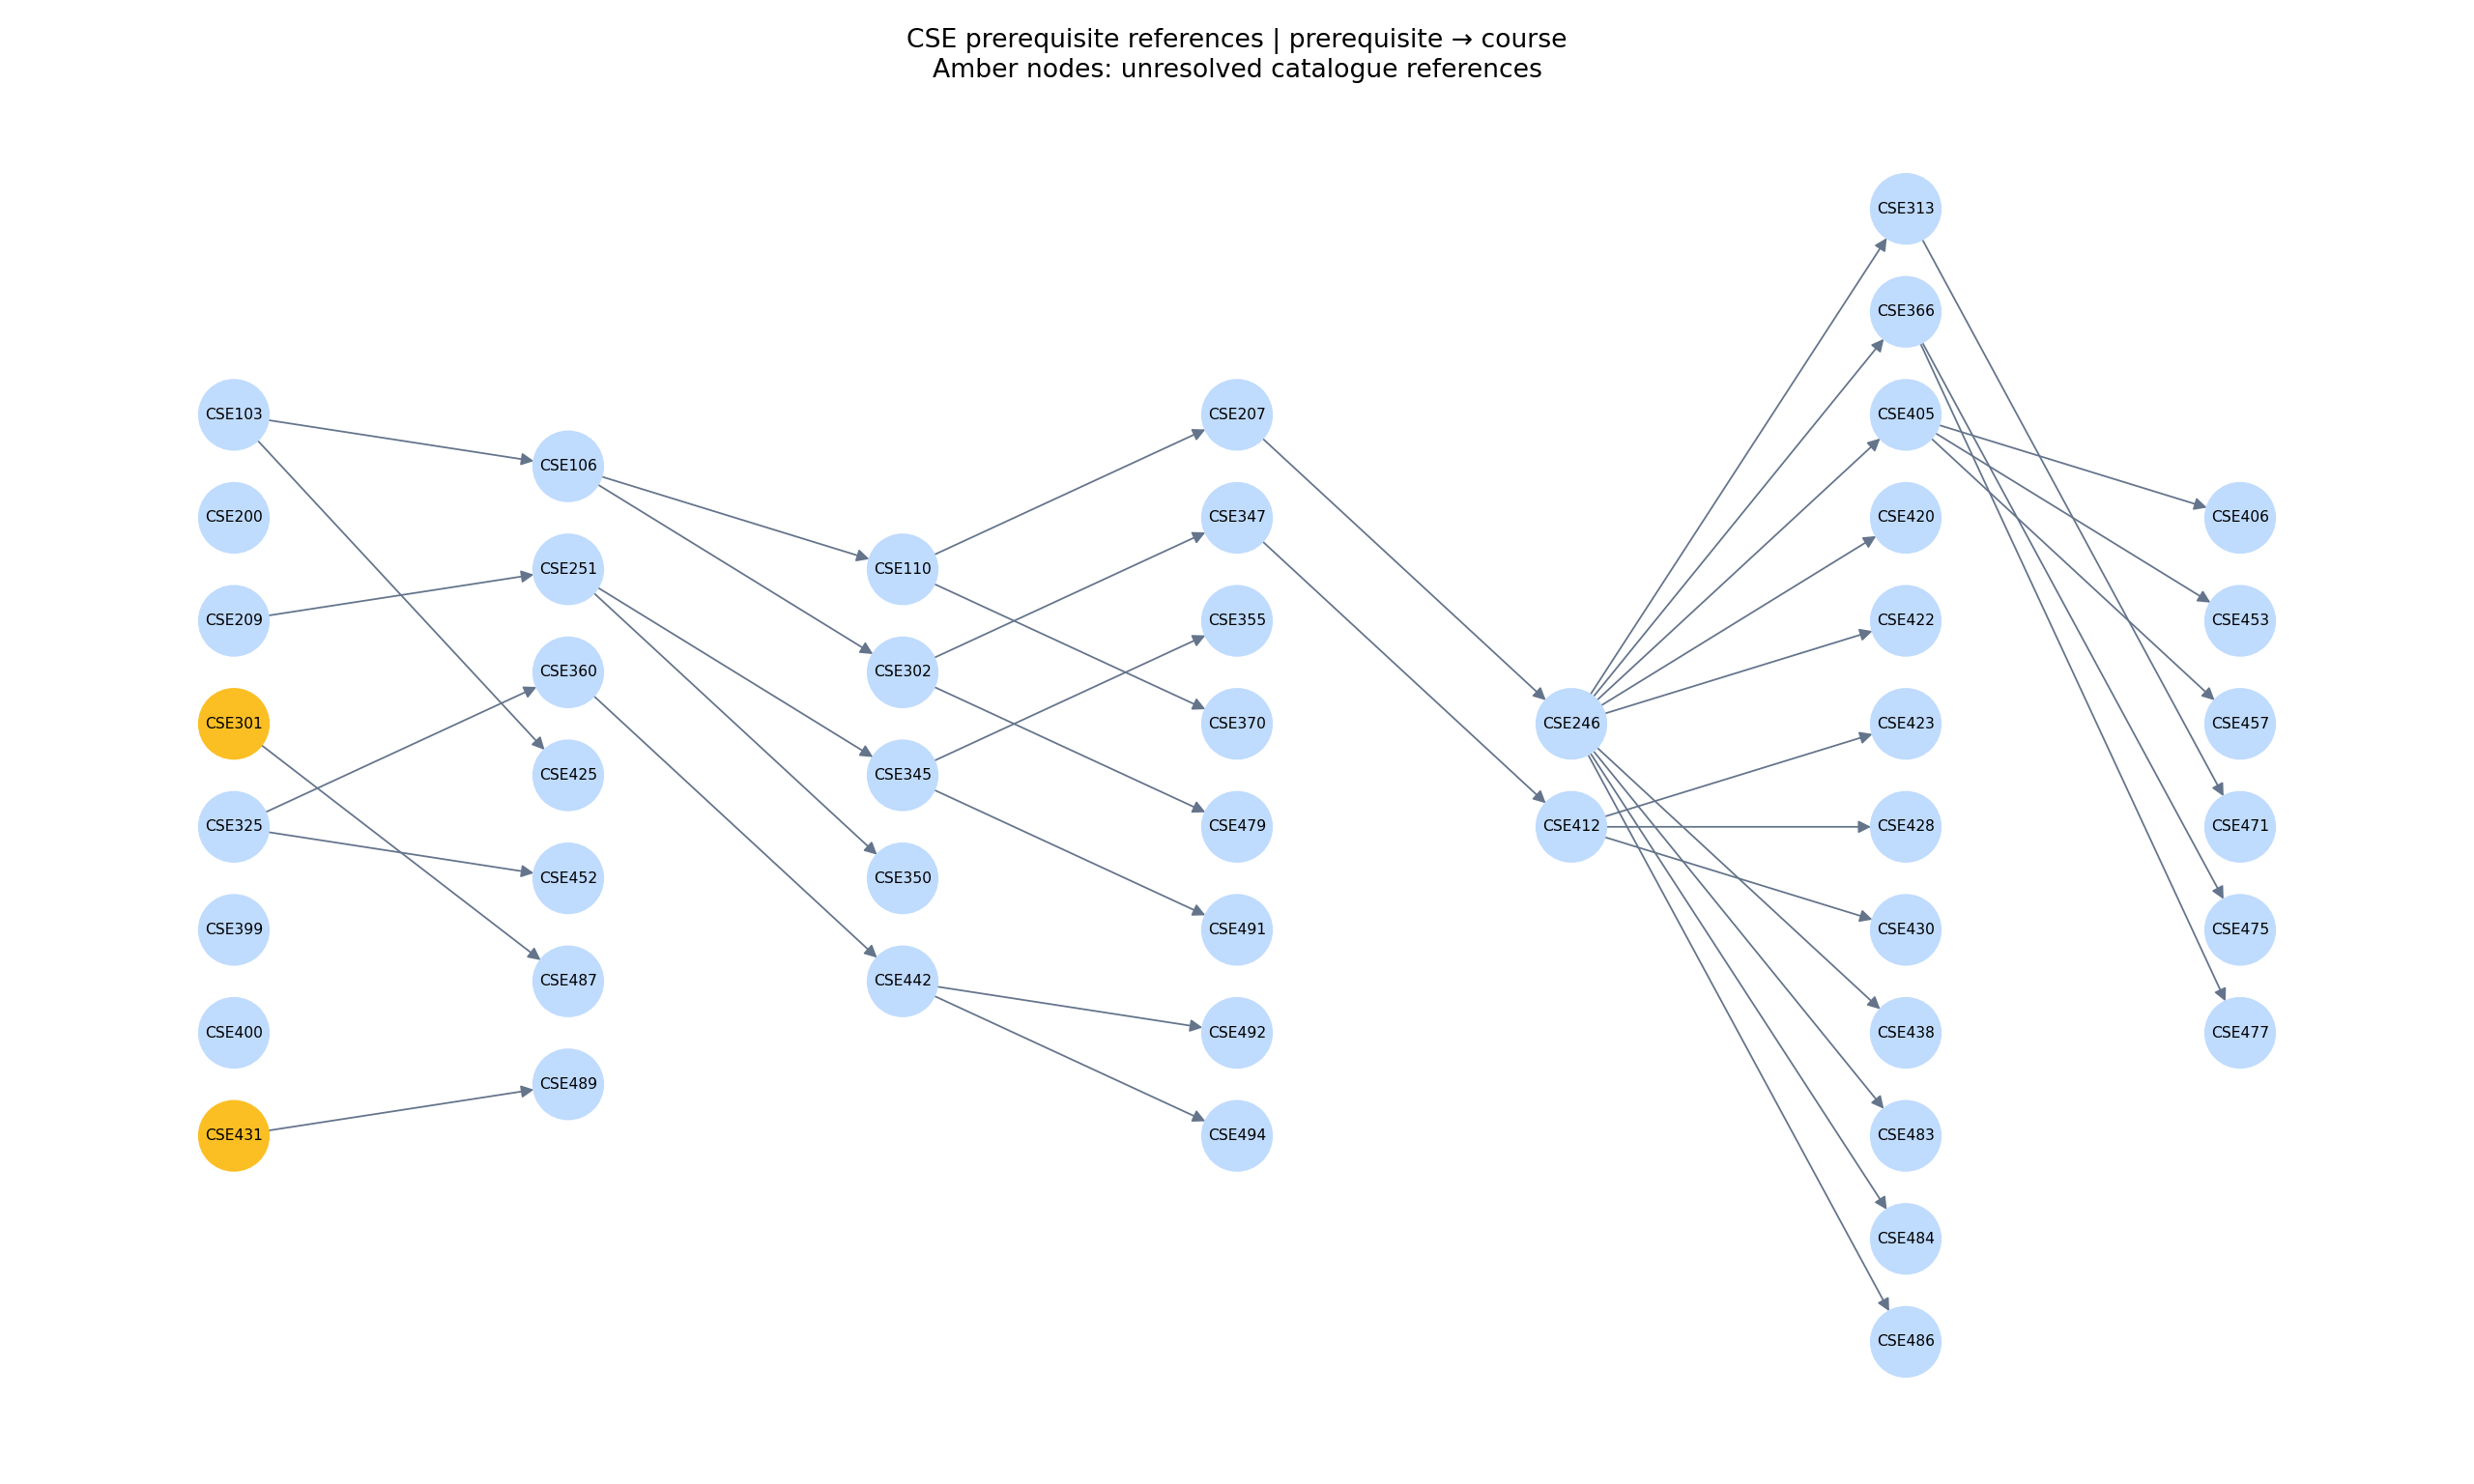

In [9]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/"reports/figures/prerequisite_graph.png")))


## Optional cited search

Enable this only in the dedicated GPU environment. It returns source passages, similarities and locators. It does not write an answer or supply gold evaluation labels.


In [10]:
RUN_SEARCH = False
if RUN_SEARCH:
    from ewu_kb.search import run
    run("What is the plagiarism policy?", top=3, document="P1")
